# MLP avec embeddings — QRT

Exploration d’un classifieur utilisant les variables numériques et des embeddings pour `ALLOCATION` et `GROUP`.

Trois blocs de dates : apprentissage, validation interne (choix d’architecture et arrêt anticipé), puis les **120 dernières dates pour une évaluation finale**. Chaque ligne prédit le signe de la prochaine session avec son propre historique. Les labels de la validation finale ne servent ni au prétraitement ni à l’entraînement.

Exécuter dans l’ordre avec le noyau Python du projet. Dépendances : `torch`, `numpy`, `pandas`, `scikit-learn`, `matplotlib`. Si nécessaire, installer dans le noyau avec `%pip install torch pandas numpy scikit-learn matplotlib`, puis redémarrer. Aucun autre notebook ni fichier de soumission n’est modifié.

In [1]:
from pathlib import Path
import sys, copy, random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score, confusion_matrix

ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'X_train.csv').exists():
    ROOT = ROOT.parent
assert (ROOT / 'data' / 'X_train.csv').exists(), "Ouvrir depuis le projet ou son dossier MLP"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from utils import data_handling

SEED = 42
FINAL_DATES = 120
INNER_DATES = 120
# None = tout le passé ; 500 ou 1000 pour explorer la récence.
HISTORY_DATES = None
BATCH_SIZE = 2048
MAX_EPOCHS = 60
PATIENCE = 8
DEVICE = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
# Mettre DEVICE = torch.device('cpu') si le backend accéléré pose problème.
print('Projet :', ROOT, '\nPyTorch :', torch.__version__, '\nCalcul :', DEVICE)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all(SEED)

/Users/salimelouahdani/anaconda3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Projet : /Users/salimelouahdani/Documents/05 - Projects/Challenge_Data/QRT_2026 
PyTorch : 1.13.1 
Calcul : cpu


## Données et découpage temporel

In [2]:
X = pd.read_csv(ROOT / 'data/X_train.csv', index_col='ROW_ID')
y_raw = pd.read_csv(ROOT / 'data/y_train.csv', index_col='ROW_ID')['target']
assert X.index.is_unique and y_raw.index.is_unique
assert X.index.equals(y_raw.index), "Alignement X/y à vérifier"
assert y_raw.notna().all()
y = (y_raw > 0).astype('float32')
data_handling.add_features(X)
NUM_COLS = data_handling.get_features()
CAT_COLS = ['ALLOCATION', 'GROUP']
assert not set(NUM_COLS) & set(CAT_COLS)
dates = sorted(X.TS.unique(), key=lambda s: int(s.split('_')[1]))
assert len(dates) > FINAL_DATES + INNER_DATES
final_dates = dates[-FINAL_DATES:]
development_dates = dates[:-FINAL_DATES]
if HISTORY_DATES is not None:
    assert HISTORY_DATES > INNER_DATES
    development_dates = development_dates[-HISTORY_DATES:]
fit_dates = development_dates[:-INNER_DATES]
inner_dates = development_dates[-INNER_DATES:]
fit_idx = X.index[X.TS.isin(fit_dates)]
inner_idx = X.index[X.TS.isin(inner_dates)]
final_idx = X.index[X.TS.isin(final_dates)]
assert not (set(fit_idx) & set(inner_idx) or set(fit_idx) & set(final_idx) or set(inner_idx) & set(final_idx))
print(pd.DataFrame([
    {'bloc': name, 'dates': len(ds), 'première': ds[0], 'dernière': ds[-1],
     'lignes': len(idx)}
    for name, ds, idx in [('apprentissage', fit_dates, fit_idx),
                         ('validation interne', inner_dates, inner_idx),
                         ('validation finale', final_dates, final_idx)]
]))

                 bloc  dates   première   dernière  lignes
0       apprentissage   2282  DATE_0001  DATE_2282  476649
1  validation interne    120  DATE_2283  DATE_2402   24764
2   validation finale    120  DATE_2403  DATE_2522   25660


## Prétraitement appris uniquement sur le bloc d’apprentissage

Écrêtage aux quantiles 0,5 % et 99,5 %, imputation médiane, standardisation et indicateurs de valeurs manquantes. Les catégories inconnues ont un identifiant réservé 0. Le même prétraitement est conservé pour toutes les architectures.

In [3]:
class Preprocessor:
    def fit(self, frame):
        a = frame[NUM_COLS].replace([np.inf, -np.inf], np.nan)
        self.low = a.quantile(.005)
        self.high = a.quantile(.995)
        a = a.clip(self.low, self.high, axis=1)
        self.median = a.median().fillna(0)
        a = a.fillna(self.median)
        self.mean = a.mean()
        self.std = a.std().replace(0, 1).fillna(1)
        self.maps = {c: {v: i+1 for i, v in enumerate(sorted(frame[c].dropna().astype(str).unique()))}
                     for c in CAT_COLS}
        self.cardinalities = [len(self.maps[c])+1 for c in CAT_COLS]
        return self
    def transform(self, frame):
        a = frame[NUM_COLS].replace([np.inf, -np.inf], np.nan)
        missing = a.isna().to_numpy(dtype=np.float32)
        a = a.clip(self.low, self.high, axis=1).fillna(self.median)
        values = ((a-self.mean)/self.std).to_numpy(dtype=np.float32)
        values = np.concatenate([values, missing], axis=1)
        cats = np.column_stack([frame[c].astype(str).map(self.maps[c]).fillna(0).to_numpy(dtype=np.int64)
                                for c in CAT_COLS])
        assert np.isfinite(values).all()
        return values, cats

prep = Preprocessor().fit(X.loc[fit_idx])
fit_arrays = prep.transform(X.loc[fit_idx])
inner_arrays = prep.transform(X.loc[inner_idx])

def dataset(arrays, targets):
    num, cats = arrays
    return TensorDataset(torch.from_numpy(num), torch.from_numpy(cats),
                         torch.from_numpy(np.asarray(targets, dtype=np.float32)))
fit_ds = dataset(fit_arrays, y.loc[fit_idx])
inner_ds = dataset(inner_arrays, y.loc[inner_idx])
print('Entrées numériques + indicateurs :', fit_arrays[0].shape[1],
      '\nTailles des vocabulaires :', prep.cardinalities)

Entrées numériques + indicateurs : 72 
Tailles des vocabulaires : [279, 5]


## Modèle et boucle d’entraînement
La sortie est un logit ; `BCEWithLogitsLoss` applique une perte binaire stable. L’arrêt anticipé utilise la log-loss interne, puis le meilleur état est restauré.

In [4]:
class EmbeddingMLP(nn.Module):
    def __init__(self, n_num, cardinalities, hidden=(128, 64), embedding_dims=(8, 2),
                 dropout=.2, use_embeddings=True):
        super().__init__()
        self.use_embeddings = use_embeddings
        self.embeddings = nn.ModuleList([
            nn.Embedding(n, d, padding_idx=0) for n, d in zip(cardinalities, embedding_dims)
        ]) if use_embeddings else nn.ModuleList()
        width = n_num + (sum(embedding_dims) if use_embeddings else 0)
        layers = []
        for h in hidden:
            layers.extend([nn.Linear(width, h), nn.ReLU(), nn.Dropout(dropout)])
            width = h
        layers.append(nn.Linear(width, 1))
        self.network = nn.Sequential(*layers)
    def forward(self, num, cats):
        if self.use_embeddings:
            num = torch.cat([num] + [emb(cats[:, i]) for i, emb in enumerate(self.embeddings)], dim=1)
        return self.network(num).squeeze(1)

@torch.no_grad()
def predict(model, arrays, batch_size=BATCH_SIZE):
    model.eval()
    dummy = np.zeros(len(arrays[0]), dtype=np.float32)
    loader = DataLoader(dataset(arrays, dummy), batch_size=batch_size, shuffle=False)
    chunks = []
    for num, cats, _ in loader:
        chunks.append(torch.sigmoid(model(num.to(DEVICE), cats.to(DEVICE))).cpu().numpy())
    return np.concatenate(chunks)

def train_model(config, train_ds, valid_ds, valid_arrays, valid_y, cardinalities,
                max_epochs=MAX_EPOCHS, patience=PATIENCE, verbose=True):
    seed_all(SEED)
    cfg = dict(config)
    lr = cfg.pop('lr', 1e-3); weight_decay = cfg.pop('weight_decay', 1e-4)
    model = EmbeddingMLP(train_ds.tensors[0].shape[1], cardinalities, **cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.BCEWithLogitsLoss()
    generator = torch.Generator().manual_seed(SEED)
    loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=generator)
    best_loss, best_state, stale, best_epoch = float('inf'), None, 0, 0
    history = []
    for epoch in range(1, max_epochs+1):
        model.train(); total = 0
        for num, cats, labels in loader:
            num, cats, labels = num.to(DEVICE), cats.to(DEVICE), labels.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(model(num, cats), labels)
            loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.)
            opt.step(); total += loss.item()*len(labels)
        p = predict(model, valid_arrays)
        val_loss = log_loss(valid_y, p, labels=[0, 1])
        acc = accuracy_score(valid_y, p > .5)
        history.append({'epoch': epoch, 'train_loss': total/len(train_ds),
                        'valid_loss': val_loss, 'valid_accuracy': acc})
        if not np.isfinite(val_loss): raise RuntimeError('Perte non finie')
        if val_loss < best_loss - 1e-5:
            best_loss, best_state, best_epoch, stale = val_loss, copy.deepcopy(model.state_dict()), epoch, 0
        else: stale += 1
        if verbose: print(f'Epoch {epoch:02d} | train {total/len(train_ds):.5f} | valid {val_loss:.5f} | accuracy {acc:.2%}')
        if stale >= patience: break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), best_epoch

BASE_CONFIG = dict(hidden=(128, 64), embedding_dims=(8, 2), dropout=.2,
                   lr=1e-3, weight_decay=1e-4, use_embeddings=True)

## Exploration sur la validation interne
Trois essais, dont une ablation sans embeddings. Désactiver `RUN_EXPLORATION` pour un seul entraînement. Le choix repose sur la log-loss interne ; aucun score final n’est utilisé.


--- MLP embeddings ---
Epoch 01 | train 0.69176 | valid 0.69148 | accuracy 52.09%
Epoch 02 | train 0.69062 | valid 0.69166 | accuracy 51.47%
Epoch 03 | train 0.69014 | valid 0.69067 | accuracy 52.37%
Epoch 04 | train 0.68960 | valid 0.69120 | accuracy 52.04%
Epoch 05 | train 0.68908 | valid 0.69070 | accuracy 51.96%
Epoch 06 | train 0.68865 | valid 0.69069 | accuracy 52.15%
Epoch 07 | train 0.68811 | valid 0.69167 | accuracy 51.60%
Epoch 08 | train 0.68764 | valid 0.69189 | accuracy 51.76%
Epoch 09 | train 0.68714 | valid 0.69090 | accuracy 52.16%
Epoch 10 | train 0.68658 | valid 0.69134 | accuracy 52.01%
Epoch 11 | train 0.68615 | valid 0.69178 | accuracy 51.93%

--- MLP sans embeddings ---
Epoch 01 | train 0.69158 | valid 0.69180 | accuracy 51.55%
Epoch 02 | train 0.69079 | valid 0.69178 | accuracy 51.28%
Epoch 03 | train 0.69044 | valid 0.69112 | accuracy 52.29%
Epoch 04 | train 0.69005 | valid 0.69182 | accuracy 51.84%
Epoch 05 | train 0.68961 | valid 0.69109 | accuracy 51.85%
Epo

,model,logloss,accuracy,best_epoch
0,MLP embeddings,0.690672,0.523663,3
2,MLP compact,0.691054,0.522775,18
1,MLP sans embeddings,0.691086,0.518535,5


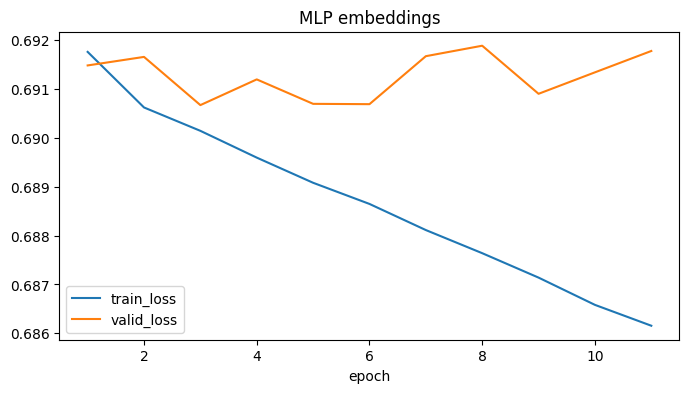

In [5]:
RUN_EXPLORATION = True
configs = [
    ('MLP embeddings', BASE_CONFIG),
    ('MLP sans embeddings', dict(BASE_CONFIG, use_embeddings=False)),
    ('MLP compact', dict(BASE_CONFIG, hidden=(64, 32), dropout=.3)),
]
if not RUN_EXPLORATION: configs = configs[:1]
experiments = {}; rows = []
for name, config in configs:
    print('\n---', name, '---')
    model, history, best_epoch = train_model(
        config, fit_ds, inner_ds, inner_arrays, y.loc[inner_idx].to_numpy(), prep.cardinalities)
    p = predict(model, inner_arrays)
    experiments[name] = dict(model=model, history=history, best_epoch=best_epoch, config=config)
    rows.append(dict(model=name, logloss=log_loss(y.loc[inner_idx], p, labels=[0, 1]),
                     accuracy=accuracy_score(y.loc[inner_idx], p > .5), best_epoch=best_epoch))
results = pd.DataFrame(rows).sort_values('logloss')
display(results)
best_name = results.iloc[0]['model']
selected = experiments[best_name]
selected['history'].plot(x='epoch', y=['train_loss', 'valid_loss'], figsize=(8, 4))
plt.title(best_name); plt.show()

## Évaluation finale — à consulter après avoir choisi les expériences
Le modèle sélectionné est évalué tel quel, sans ajustement sur les 120 dates finales. Ce bloc cesse d’être une évaluation indépendante si ses résultats servent à choisir les prochaines expériences.

,model,accuracy,logloss
0,MLP embeddings,0.519330,0.692024
1,Toujours positif,0.522097,NaN
2,Fréquence globale apprentissage,0.522097,0.692709


AUC : 0.5228538174480089
Fraction prédite positive : 0.5981683554169914
Matrice de confusion :
 [[5120 7143]
 [5191 8206]]


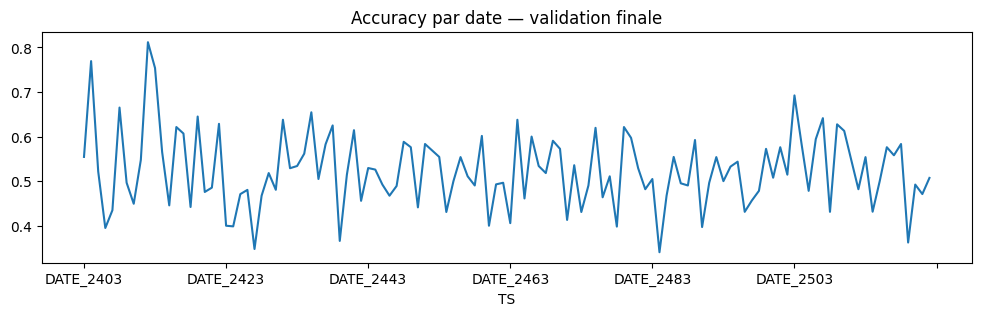

In [6]:
final_arrays = prep.transform(X.loc[final_idx])
final_y = y.loc[final_idx].to_numpy()
final_p = predict(selected['model'], final_arrays)
constant_p = np.full(len(final_y), float(y.loc[fit_idx].mean()))
comparison = pd.DataFrame([
    dict(model=best_name, accuracy=accuracy_score(final_y, final_p > .5),
         logloss=log_loss(final_y, final_p, labels=[0, 1])),
    dict(model='Toujours positif', accuracy=accuracy_score(final_y, np.ones(len(final_y))), logloss=np.nan),
    dict(model='Fréquence globale apprentissage', accuracy=accuracy_score(final_y, constant_p > .5),
         logloss=log_loss(final_y, constant_p, labels=[0, 1]))
])
display(comparison)
print('AUC :', roc_auc_score(final_y, final_p) if len(np.unique(final_y)) == 2 else 'non définie')
print('Fraction prédite positive :', float((final_p > .5).mean()))
print('Matrice de confusion :\n', confusion_matrix(final_y, final_p > .5))
predictions = pd.DataFrame({'TS': X.loc[final_idx, 'TS'], 'target': final_y,
                            'probability': final_p, 'prediction': (final_p > .5).astype(int)}, index=final_idx)
per_date = predictions.assign(correct=lambda d: d.target == d.prediction).groupby('TS').agg(
    accuracy=('correct', 'mean'), n=('correct', 'size'))
per_date.accuracy.plot(figsize=(12, 3), title='Accuracy par date — validation finale')
plt.show()
# Comparer l’accuracy globale, pondérée par les lignes, à celle de LightGBM sur le même bloc.

## Soumission optionnelle : réentraînement sur toutes les données

Désactivé par défaut. Réapprend le prétraitement sur tout l’entraînement officiel et entraîne le modèle choisi pendant le nombre d’epochs sélectionné **sur la validation interne**. Écrit uniquement `MLP/submission_mlp.csv`. Aucun arrêt anticipé sur le test officiel.

In [ ]:
MAKE_SUBMISSION = False
if MAKE_SUBMISSION:
    full_prep = Preprocessor().fit(X)
    full_arrays = full_prep.transform(X)
    full_ds = dataset(full_arrays, y)
    seed_all(SEED)
    cfg = dict(selected['config'])
    lr = cfg.pop('lr', 1e-3); wd = cfg.pop('weight_decay', 1e-4)
    full_model = EmbeddingMLP(full_arrays[0].shape[1], full_prep.cardinalities, **cfg).to(DEVICE)
    optimizer = torch.optim.AdamW(full_model.parameters(), lr=lr, weight_decay=wd)
    criterion = nn.BCEWithLogitsLoss()
    loader = DataLoader(full_ds, batch_size=BATCH_SIZE, shuffle=True,
                        generator=torch.Generator().manual_seed(SEED))
    for epoch in range(selected['best_epoch']):
        full_model.train()
        for num, cats, labels in loader:
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(full_model(num.to(DEVICE), cats.to(DEVICE)), labels.to(DEVICE))
            loss.backward(); nn.utils.clip_grad_norm_(full_model.parameters(), 5.)
            optimizer.step()
        print('Epoch complète', epoch+1)
    test = pd.read_csv(ROOT / 'data/X_Test.csv', index_col='ROW_ID')
    data_handling.add_features(test)
    sample = pd.read_csv(ROOT / 'data/sample_submission.csv', index_col='ROW_ID')
    assert test.index.is_unique and set(test.index) == set(sample.index)
    probabilities = predict(full_model, full_prep.transform(test))
    submission = pd.DataFrame({'prediction': (probabilities > .5).astype(int)}, index=test.index).reindex(sample.index)
    assert submission.notna().all().all()
    output = ROOT / 'MLP/submission_mlp.csv'
    submission.to_csv(output)
    print('Soumission :', output, submission.shape)
else:
    print('Soumission désactivée : MAKE_SUBMISSION = True pour réentraîner et exporter.')